# Week 11 — Phase 4, first regressor

Trains the baseline MLP on `log10` distance-to-nearest-QPIT, against the
Week 10 labelled dataset, and produces the week's deliverable: **baseline
metrics plus an accuracy-vs-tolerance curve**.

**Scope.** Weekly Plan row 13. Feature representation; shortcut baseline;
grouped train/test split; MLP regressor; classification as a thresholded
readout. Nothing else. Explicitly NOT here: the hyperparameter sweep and the
Titan port, the phase-space error map, the resonance-proximity connection and
the central figure (all Week 12); speedup benchmarking (Week 13); cross-family
and cross-energy holdout (Week 15).

**Decisions taken into this notebook.**

1. *Floor samples are kept*, and every test metric is reported split by
   `at_floor`. They are left-censored observations — the true distance is below
   what the surface determines — so a censored (Tobit) loss is the principled
   treatment, but that is a Week 12 change if the split reporting shows it
   matters.
2. *Three seeds*, as a sanity band on whether "the baseline failed" survives
   re-initialisation. The confidence-interval protocol is Week 12.
3. *Learning curve in*, over group fractions. It is the bias–variance
   checkpoint made concrete for the dad session.
4. *B2 under both splits.* The grouped-vs-random gap is the empirical
   correlation length of the dataset and the evidence that grouping is
   necessary rather than decorative.

**Predictions, stated before running.** Scored in section 10.

| | claim | falsified if |
|---|---|---|
| **P1** | the shortcut baseline B1 scores near R² ≈ 0 — location relative to L1/L2 plus energy does not determine distance-to-torus | B1 R² > 0.5, which means the sampling left a location shortcut in and the dataset needs fixing |
| **P2** | 1-NN scores markedly higher under a row-random split than under the grouped split | the gap is ≈ 0, meaning either the group key is finer than the correlation length or the split is not doing what it claims |
| **P3** | ∇(log d) ~ 1/d normal to the surface, so the target's Lipschitz constant is unbounded as d → 0 while a smooth-activation MLP's gradient is bounded. Residuals are strongly heteroscedastic with a **systematic positive bias near the floor** — the network over-predicts distance for near-surface points. Overall R² is **high**, above 0.9 | uniform residual scale across the target range, or no near-field bias |

P3 contradicts Risk 19, deliberately. Risk 19 expects mediocre R² from
Cantor-set non-smoothness, but the labeller measures distance to a densified
*interpolated continuum* at ~12.3 km spacing and cannot resolve the gaps — and
the Week 10 gap experiment (80/80, exponent 2.003) says the interpolant is
populated by real tori anyway. So the target as generated should be
piecewise-smooth with cut-locus kinks, not Cantor-rough. If P3 holds, the
paper's framing improves: *"R² is high, but the near field — precisely the
regime a warm start needs — is where it degrades, and here is the mechanism"*
is a finding, where *"R² is mediocre and that is physics"* is a defence.

**Runtime** ~15–30 min on a laptop: seven MLP fits (3 seeds + 4 learning-curve
folds) plus the baselines.

In [1]:
import sys, os, time, json, warnings
sys.path.insert(0, '../src')

import numpy as np
import matplotlib.pyplot as plt
import torch

from features import (jacobi_constant, build_features, assert_no_leakage,
                      Standardizer, MU_EARTH_MOON, LU_KM)
from splits import (grouped_split, random_row_split, groups_disjoint,
                    group_census, split_report, nearest_point_overlap,
                    subsample_groups)
from metrics import (regression_metrics, accuracy_vs_threshold,
                     summarize_threshold_curve, accuracy_vs_error_tolerance,
                     residual_bins, format_table)
from baselines import (collinear_points, shortcut_features, MeanPredictor,
                       KNNRegressor, fit_flexible)
from models import MLPConfig, train_mlp, predict, train_multi_seed, count_parameters

torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))
np.set_printoptions(precision=6, suppress=True)
t0 = time.time()

# ---- SET THIS to the Week 10 output. A single path, or a list to concatenate
# if the per-(family, energy) checkpoints were never merged.
DATA = '../data/qpit_dataset_w10.npz'

SEED_SPLIT  = 0
SEEDS_MODEL = (0, 1, 2)
FRAC_TEST, FRAC_VAL = 0.20, 0.10
FLOOR_KM = 1.55e-4            # measured in Week 10: 155 mm
os.makedirs('../data/wk11', exist_ok=True)
print(f"torch {torch.__version__}   floor {FLOOR_KM*1e6:.0f} mm")

torch 2.12.0+cpu   floor 155 mm


## 1. Load

The Week 10 generator checkpointed per (family, energy), so `DATA` may be
several files. They are concatenated on the row axis; `group_id` already
encodes family and energy, so groups stay distinct across files without any
renumbering.

In [2]:
import glob
from collections import Counter

def load_dataset(paths):
    paths = [paths] if isinstance(paths, str) else list(paths)
    missing = [p for p in paths if not os.path.exists(p)]
    if missing:
        # Say what IS there.  An error that reports only what is absent makes
        # the reader go hunting for a filename the machine already knows.
        found = []
        for d in sorted({os.path.dirname(p) or '.' for p in paths}):
            found += sorted(glob.glob(os.path.join(d, '*.npz')))
        listing = '\n  '.join(found) if found else '(none in that directory)'
        raise FileNotFoundError(
            f"not found: {missing}\n"
            f".npz files actually present:\n  {listing}\n"
            f"Set DATA in the config cell. If the Week 10 per-(family, energy) "
            f"checkpoints were never merged, pass the list of them instead of "
            f"one path -- load_dataset concatenates.")

    parts = [dict(np.load(p, allow_pickle=True)) for p in paths]
    keys = set(parts[0])
    for p in parts[1:]:
        keys &= set(p)
    dropped = set(parts[0]) - keys
    if dropped:
        print(f"columns absent from some files, dropped: {sorted(dropped)}")

    # WHAT COUNTS AS A COLUMN: leading dimension == the row count, anchored on
    # `states`.  An earlier version tested for 0-d scalars instead and tried to
    # concatenate `energies` (3), `family_sizes` (6), `family_tags` (6) and
    # `family_max_gap_km` (6) as though they were columns.  Metadata in this
    # dataset is 1-D per-sheet arrays, not scalars.
    anchors = [len(p['states']) if 'states' in p else
               max(Counter(len(v) for v in p.values() if v.ndim).items(),
                   key=lambda kv: kv[1])[0]
               for p in parts]

    cols, meta = {}, {}
    for k in sorted(keys):
        vals = [p[k] for p in parts]
        if all(v.ndim >= 1 and len(v) == a for v, a in zip(vals, anchors)):
            cols[k] = np.concatenate(vals)
        else:
            if any(not np.array_equal(v, vals[0]) for v in vals[1:]):
                print(f"  NOTE: metadata '{k}' differs between files; kept the first")
            meta[k] = vals[0]

    counts = {k: len(v) for k, v in cols.items()}
    if len(set(counts.values())) != 1:
        raise ValueError(f"columns disagree on row count: {counts}")
    return cols, meta

D, META = load_dataset(DATA)
n = len(D['states'])
print(f"{n} rows, {len(D)} columns")
print(f"columns: {sorted(D)}")
for k in sorted(META):
    v = META[k]
    print(f"  meta {k:22s} shape {v.shape} {np.array2string(v, max_line_width=100)[:90]}")
for k in ('family_id', 'energy_id'):
    if k in D:
        u, c = np.unique(D[k], return_counts=True)
        print(f"{k}: {dict(zip(u.tolist(), c.tolist()))}")

20400 rows, 18 columns
columns: ['C', 'alpha', 'amplitude_km', 'at_floor', 'd_drawn_km', 'd_km', 'energy_id', 'family', 'family_id', 'gap', 'group_id', 'jacobi', 'label_B', 'random_dir', 'score_C', 'source', 'states', 'theta']
  meta A_target_km            shape () 400.
  meta energies               shape (3,) [3.029398 3.064703 3.130607]
  meta family_max_gap_km      shape (6,) [11.833904 11.793818 12.10368  12.263254 11.063313 53.655479]
  meta family_sizes           shape (6,) [64 44 36 48 39 25]
  meta family_tags            shape (6,) ['L1_E0' 'L1_E1' 'L1_E2' 'L2_E0' 'L2_E1' 'L2_E2']
  meta floor_km               shape () 0.000155
  meta label_B_km             shape () 1.
  meta mu                     shape () 0.012151
  meta n_bundle               shape () 400
  meta n_offset               shape () 2600
  meta n_surface              shape () 400
  meta q_max                  shape () 5
  meta target_gap_km          shape () 12.3
family_id: {0: 10200, 1: 10200}
energy_id: {0: 6800

### 1b. What is actually in the file

Written against the schema the Week 10 generator produced, not against the one
inferred from `label_and_pack` -- they differ. Two columns could be the
regression target (`d_km`, the geometric surface distance, and `score_C`, which
in Week 10 was the probe's invariance residual `dist_max`), and they are not the
same quantity. This prints enough to decide which is which rather than guessing,
because guessing wrong would invalidate every number downstream.

In [3]:
print(f"{'column':16s} {'dtype':10s} {'shape':14s} min / median / max")
for k in sorted(D):
    v = D[k]
    if v.dtype.kind in 'fiu' and v.ndim == 1:
        print(f"{k:16s} {str(v.dtype):10s} {str(v.shape):14s} "
              f"{v.min():.6g} / {np.median(v):.6g} / {v.max():.6g}")
    elif v.dtype.kind == 'b':
        print(f"{k:16s} {str(v.dtype):10s} {str(v.shape):14s} True: {v.sum()}")
    else:
        u = np.unique(v) if v.ndim == 1 else np.array(['-'])
        print(f"{k:16s} {str(v.dtype):10s} {str(v.shape):14s} "
              f"{u[:6] if u.size <= 12 else str(u.size) + ' distinct'}")

# Is score_C the LOG of d_km, or a different quantity?  Compare it against
# log10(max(d_km, floor)) directly.  An earlier version took log10 OF score_C,
# which is already in log units, and reported a meaningless 0.87 correlation.
if {'d_km', 'score_C'} <= set(D):
    a, b = D['d_km'].astype(float), D['score_C'].astype(float)
    lg = np.log10(np.maximum(a, FLOOR_KM))
    print(f"\nscore_C vs log10(max(d_km, {FLOOR_KM:g})): "
          f"allclose {np.allclose(b, lg, atol=1e-9)}, "
          f"max |diff| {np.abs(b - lg).max():.3e}")
    print(f"  score_C range {b.min():.5f} .. {b.max():.5f}   "
          f"10**min = {10**b.min():.3e} km")
    if not np.allclose(b, lg, atol=1e-6):
        print("  NOT the same column -- resolve which is the target before "
              "going further")

if 'label_B' in D:
    print(f"\nlabel_B: {int(np.sum(D['label_B']))} positive of {len(D['label_B'])}")

column           dtype      shape          min / median / max
C                float64    (20400,)       3.0294 / 3.0647 / 3.13061
alpha            float64    (20400,)       0 / 0.430926 / 0.99992
amplitude_km     float64    (20400,)       0.043659 / 183.497 / 396.724
at_floor         bool       (20400,)       True: 2502
d_drawn_km       float64    (20400,)       0 / 0.0546744 / 99.81
d_km             float64    (20400,)       0 / 0.0487426 / 99.6834
energy_id        int64      (20400,)       0 / 1 / 2
family           <U2        (20400,)       ['L1' 'L2']
family_id        int64      (20400,)       0 / 0.5 / 1
gap              int64      (20400,)       0 / 22 / 62
group_id         int64      (20400,)       0 / 1.60321e+08 / 3.20641e+08
jacobi           float64    (20400,)       3.0294 / 3.0647 / 3.13061
label_B          bool       (20400,)       True: 14309
random_dir       bool       (20400,)       True: 3825
score_C          float64    (20400,)       -3.80967 / -1.31209 / 1.99862
sou

## 2. Audit

Five checks, all cheap, all before any model touches the data.

**2a is the one that can change the feature set.** `sampling.label_and_pack`
writes `C=np.full(n, C)` — the *family's* energy broadcast to every row, not
each state's own Jacobi constant. Off-surface samples were stepped along a
normal direction, and unless they were reprojected onto the energy manifold
their true C differs from that column. If it does, `C` is a six-valued sheet
tag rather than a state feature, and handing it to the shortcut baseline
alongside a radial coordinate could let B1 succeed for a bookkeeping reason —
condemning a dataset that does not deserve it.

**2b is a free regression test on the labeller.** For offset samples drawn
along a projected normal, the *drawn* distance and the *measured* one should
agree to ~2% by construction. A fifth independent validation, at no cost.

**2e** checks whether `d_res` is actually in the dataset. Week 12 assumes it.
Finding out now costs a minute; finding out in Week 12 costs a day.

In [4]:
# 2a. WHICH energy column is safe to use as a feature?
#
# Not "is the stored C per-state or a sheet tag" -- that was the wrong question
# and answering it by recomputing C from the state manufactured a shortcut.
# The offsets were never reprojected onto the energy manifold, so a state's own
# Jacobi constant differs from its sheet's IN PROPORTION TO THE OFFSET, which
# is the target.  The sheet tag is the clean column; the per-state value is the
# leak.  Measured in nb11_diag_shortcut: sheet C alone R2 = -0.0001,
# recomputed per-state Jacobi alone R2 = +0.7976.
C_stored = (D['C'] if 'C' in D else D['jacobi']).astype(float)
C_state = jacobi_constant(D['states'], MU_EARTH_MOON)
sheets = np.unique(np.round(C_stored, 9))
print(f"stored C: {sheets.size} distinct values -> {np.array2string(sheets[:8], precision=9)}")

SHEET_LIKE = sheets.size <= 12
if SHEET_LIKE:
    JAC = C_stored
    print("-> stored C is the SHEET energy. Using it. This is the clean column.")
else:
    JAC = C_stored
    print("-> stored C varies continuously. It may already be reprojected, or it "
          "may\n   itself carry the offset. Check the leak size below before "
          "trusting it.")

# size of the leak, so it is a measured quantity in the record rather than an
# assertion carried over from a diagnostic script
dC = np.abs(C_state - C_stored)
print(f"\n|C_state - C_sheet|: median {np.median(dC):.3e}  max {dC.max():.3e}")
_m = (dC > 0) & np.isfinite(dC)
if _m.sum() > 50:
    _y = np.log10(np.maximum(D['d_km'].astype(float), FLOOR_KM))
    print(f"corr(log10|C_state - C_sheet|, target) = "
          f"{np.corrcoef(np.log10(dC[_m]), _y[_m])[0,1]:.4f}")
    print("A high correlation is why the per-state Jacobi is NOT a feature: with "
          "only\nthree energy sheets it is a proxy for the offset. That is a "
          "coverage artefact,\nnot dynamics -- real QPIT families fill a "
          "continuous energy range.")

_off = np.abs(np.median(C_state - C_stored) - MU_EARTH_MOON * (1 - MU_EARTH_MOON) / 2)
if _off < 1e-6:
    print("\nNOTE: the median offset equals mu(1-mu)/2 -- a CONVENTION mismatch "
          "with\ncr3bp_3d, not a physical displacement. Reconcile before reading "
          "anything\nelse into it.")

stored C: 3 distinct values -> [3.029398206 3.064703461 3.130606605]
-> stored C is the SHEET energy. Using it. This is the clean column.

|C_state - C_sheet|: median 7.970e-04  max 1.771e-03
corr(log10|C_state - C_sheet|, target) = 0.0010
A high correlation is why the per-state Jacobi is NOT a feature: with only
three energy sheets it is a proxy for the offset. That is a coverage artefact,
not dynamics -- real QPIT families fill a continuous energy range.


In [5]:
# 2b. drawn vs measured distance -- regression test on the labeller
if {'d_drawn_km', 'source', 'random_dir'} <= set(D):
    m = ((D['source'] == 'offset') & (~D['random_dir'].astype(bool))
         & (~D['at_floor'].astype(bool)))
    rel = np.abs(D['d_km'][m] - D['d_drawn_km'][m]) / np.maximum(D['d_drawn_km'][m], 1e-30)
    print(f"projected-normal offsets: {m.sum()} samples")
    print(f"  relative error  median {np.median(rel)*100:.3f}%   "
          f"p95 {np.percentile(rel, 95)*100:.3f}%   max {rel.max()*100:.3f}%")
    print(f"  {'PASS' if np.median(rel) < 0.02 else 'FAIL'} against the 2% construction target")
else:
    print("d_drawn_km / source / random_dir absent -- labeller check skipped")

projected-normal offsets: 11769 samples
  relative error  median 0.009%   p95 2.744%   max 74.777%
  PASS against the 2% construction target


In [6]:
# 2c. RESOLVE THE TARGET, then census the censoring.
# log_d_km is not stored in this dataset, so it is derived here -- and the
# floor it is derived with comes from the FILE when the file has one, because a
# hardcoded constant sitting beside an authoritative value is the exact shape of
# the unit slips logged as Risk 20.
for _k in ('floor_km', 'FLOOR_KM', 'floor'):
    if _k in META:
        _f = float(np.ravel(META[_k])[0])
        if abs(_f - FLOOR_KM) > 1e-15:
            print(f"floor in file {_f:.6g} km overrides notebook constant "
                  f"{FLOOR_KM:.6g} km")
        FLOOR_KM = _f
        break
else:
    print(f"no floor in file; using the Week 10 measured value {FLOOR_KM:.6g} km")

if 'log_d_km' in D:
    y_all = D['log_d_km'].astype(float)
    TARGET_COL = 'log_d_km (stored)'
else:
    y_all = np.log10(np.maximum(D['d_km'].astype(float), FLOOR_KM))
    TARGET_COL = 'log10(max(d_km, floor)) [derived]'
print(f"target: {TARGET_COL}")

at_floor = D['at_floor'].astype(bool)
_implied = D['d_km'].astype(float) < FLOOR_KM
if not np.array_equal(at_floor, _implied):
    print(f"  NOTE: at_floor disagrees with (d_km < floor) on "
          f"{(at_floor != _implied).sum()} rows -- the stored flag was set "
          f"against a different floor. Using the STORED flag.")
print(f"target log10 d[km]: {y_all.min():.3f} to {y_all.max():.3f}  "
      f"(={10**y_all.min()*1e3:.2f} m to {10**y_all.max():.1f} km)")
print(f"at_floor: {at_floor.sum()} / {n}  ({at_floor.mean()*100:.2f}%)")
print(f"floor value log10({FLOOR_KM}) = {np.log10(FLOOR_KM):.3f}; "
      f"rows sitting exactly there: {(np.abs(y_all - np.log10(FLOOR_KM)) < 1e-12).sum()}")

# 2d. group census
print()
for k, v in group_census(D['group_id']).items():
    print(f"  {k:14s} {v}")

target: log10(max(d_km, floor)) [derived]
target log10 d[km]: -3.810 to 1.999  (=0.15 m to 99.7 km)
at_floor: 2502 / 20400  (12.26%)
floor value log10(0.000155) = -3.810; rows sitting exactly there: 2502

  n_rows         20400
  n_groups       6564
  size_min       1
  size_max       24
  size_mean      3.1078610603290677
  size_median    2.0
  n_singleton    1762


In [7]:
# 2e. is d_res present? Week 12 needs it.
if 'd_res' in D:
    print(f"d_res present: {np.nanmin(D['d_res']):.4f} to {np.nanmax(D['d_res']):.4f}")
else:
    print("d_res ABSENT from the dataset.\n"
          "  Week 12 ('connect high-error regions to resonance proximity') "
          "assumes this column.\n"
          "  It is derivable from alpha_found -> member rho -> "
          "gap_sample.resonance_distance.\n"
          "  NOT built here: that is Week 12 scope. Flagged so it is not a "
          "surprise then.")

# 2f. cross-check the libration points against the project's own module
L = collinear_points(MU_EARTH_MOON)
print(f"\nL1 {L['L1']:.9f}   L2 {L['L2']:.9f}   L3 {L['L3']:.9f}")
try:
    import orbits
    for name in ('lagrange_points', 'libration_points', 'collinear_points'):
        if hasattr(orbits, name):
            print(f"  orbits.{name} ->", getattr(orbits, name)(MU_EARTH_MOON))
            break
    else:
        print("  (no comparable function found in orbits; values stand on the "
              "root check in tests/test_baselines.py)")
except Exception as e:
    print(f"  (orbits not importable here: {e})")

d_res ABSENT from the dataset.
  Week 12 ('connect high-error regions to resonance proximity') assumes this column.
  It is derivable from alpha_found -> member rho -> gap_sample.resonance_distance.
  NOT built here: that is Week 12 scope. Flagged so it is not a surprise then.

L1 0.836915126   L2 1.155682165   L3 -1.005062646
Jacobian at L1:
[[ 0.        0.        1.        0.      ]
 [ 0.        0.        0.        1.      ]
 [11.295189  0.        0.        2.      ]
 [ 0.       -4.147595 -2.        0.      ]]

Eigenvalues at L1:
  -2.932056+0.000000j
  2.932056+0.000000j
  0.000000+2.334386j
  0.000000-2.334386j
Oscillation frequency omega = 2.334386
Linearized orbit period T = 2.691580

Complex eigenvector for +i*omega:
  x-component:  -0.105758-0.000000j
  y-component:  0.000000-0.379301j
  vx-component: -0.000000-0.246880j
  vy-component: 0.885435+0.000000j
vy0 / delta_x ratio = -8.372273

Linearized initial guess for a small L1 Lyapunov orbit:
  x0  = 0.83591513   (L1 offset by 

## 3. Features

Allowlist, not denylist. The dataset carries the label (`d_km`, `log_d_km`),
the quantity it was drawn from (`d_drawn_km`), and the surface coordinates the
state was constructed from and recovered at (`gap`, `alpha`, `theta`,
`amplitude_km`, `alpha_found`, `theta_found`). Any of those reaching the model
produces a spectacular and meaningless result, and a denylist that misses one
fails silently. `assert_no_leakage` fails loudly instead.

Energy enters as **continuous C**, not a one-hot over `energy_id`: a one-hot
cannot extrapolate to an unseen energy, and Week 15's transfer study needs
exactly that. Family enters as a **one-hot**, because L1 and L2 are different
objects and integer-coding them would assert an ordering that does not exist.

In [8]:
FAMILY_LEVELS = sorted(np.unique(D['family_id']).tolist())
X, FEAT_NAMES, SCALE_MASK = build_features(
    D['states'], JAC, D['family_id'], FAMILY_LEVELS)
assert_no_leakage(FEAT_NAMES)
print(f"X {X.shape}   features {FEAT_NAMES}")
print(f"standardised: {[n for n, s in zip(FEAT_NAMES, SCALE_MASK) if s]}")
print(f"left alone:   {[n for n, s in zip(FEAT_NAMES, SCALE_MASK) if not s]}")

y = y_all.copy()

X (20400, 9)   features ['x', 'y', 'z', 'vx', 'vy', 'vz', 'C', 'family_0', 'family_1']
standardised: ['x', 'y', 'z', 'vx', 'vy', 'vz', 'C']
left alone:   ['family_0', 'family_1']


## 4. Splits, and what they leave open

`group_id` bins (family, energy, gap, alpha, theta) — a patch of the family
surface. Samples inside one bin share a base point and a direction, so they are
near-duplicates. Splitting on rows would put them on both sides of the boundary
and the test score would measure memorisation.

What the grouped split asks is: *does the field interpolate to unseen patches of
sheets it has already seen.* Holding out a whole energy or a whole family is
strictly harder and is **Week 15**, not this week. Worth being explicit, since
the two get conflated and a reader will assume the harder claim.

**The leak grouping cannot close.** For a large offset the nearest surface point
is not the base point the state was built from, so a test sample's nearest torus
can sit inside a training patch even though its own group is held out. That is
not fixable by regrouping — the label is defined by the *found* point — so it
gets measured and reported beside the test score.

In [9]:
M = grouped_split(D['group_id'], FRAC_TEST, FRAC_VAL, seed=SEED_SPLIT)
assert groups_disjoint(D['group_id'], M), "grouped split leaked a group"

strata = None
if 'energy_id' in D and 'family_id' in D:
    strata = np.array([f"f{a}e{b}" for a, b in zip(D['family_id'], D['energy_id'])])
rep = split_report(y, M, group_id=D['group_id'], strata=strata)
for k in sorted(rep):
    v = rep[k]
    print(f"  {k:26s} {v:.4f}" if isinstance(v, float) else f"  {k:26s} {v}")

  ks_pvalue_train_test       0.1162
  ks_stat_train_test         0.0212
  n_groups                   6564
  n_rows                     20400
  n_singleton                1762
  size_max                   24
  size_mean                  3.1079
  size_median                2.0000
  size_min                   1
  stratum_f0e0_test          597
  stratum_f0e0_train         2441
  stratum_f0e0_val           362
  stratum_f0e1_test          714
  stratum_f0e1_train         2375
  stratum_f0e1_val           311
  stratum_f0e2_test          658
  stratum_f0e2_train         2448
  stratum_f0e2_val           294
  stratum_f1e0_test          697
  stratum_f1e0_train         2355
  stratum_f1e0_val           348
  stratum_f1e1_test          685
  stratum_f1e1_train         2387
  stratum_f1e1_val           328
  stratum_f1e2_test          684
  stratum_f1e2_train         2403
  stratum_f1e2_val           313
  test_groups                1313
  test_n                     4035
  test_row_frac       

In [10]:
# residual contamination: does a test sample's NEAREST SURFACE POINT sit in a
# training patch? bins the recovered coordinates directly, so it does not
# matter whether alpha_found is global or within-gap -- only that both sides
# use the same convention.
if {'alpha_found', 'theta_found'} <= set(D):
    coords = np.column_stack([D['alpha_found'], D['theta_found']])
    keys = np.column_stack([D['family_id'], D.get('energy_id', np.zeros(n, int))])
    rng_ = (coords.min(axis=0), coords.max(axis=0))
    for nb in (16, 64, 256):
        r = nearest_point_overlap(coords[M['train']], coords[M['test']], n_bins=nb,
                                  keys_train=keys[M['train']], keys_test=keys[M['test']],
                                  ranges=rng_)
        print(f"  n_bins={nb:4d}  overlap {r['overlap_fraction']*100:6.2f}%  "
              f"train bins occupied {r['n_bins_occupied_train']}")
    print("\nThis BOUNDS how much of the test score could be near-neighbour "
          "recall.\nIt is a number to quote beside the headline metric, not a "
          "reason to redesign the split.")
else:
    print("alpha_found / theta_found absent -- overlap diagnostic skipped")

alpha_found / theta_found absent -- overlap diagnostic skipped


In [11]:
scaler = Standardizer(mask=SCALE_MASK).fit(X[M['train']])   # TRAIN ROWS ONLY
Z = scaler.transform(X)
print("train feature means after scaling:", np.round(Z[M['train']].mean(axis=0), 6))
print("train feature stds  after scaling:", np.round(Z[M['train']].std(axis=0), 6))
print("test  feature means after scaling:", np.round(Z[M['test']].mean(axis=0), 6),
      "\n  (not zero, and should not be -- the scaler never saw these rows)")

train feature means after scaling: [-0.        0.        0.       -0.       -0.       -0.       -0.
  0.504129  0.495871]
train feature stds  after scaling: [1.       1.       1.       1.       1.       1.       1.       0.499983
 0.499983]
test  feature means after scaling: [ 0.02809   0.038545  0.032101 -0.045061  0.027167  0.021519  0.003818
  0.48798   0.51202 ] 
  (not zero, and should not be -- the scaler never saw these rows)


## 5. Baselines

**B0** mean predictor — defines the zero of R².

**B1** the shortcut probe: `(|r − L1|, |r − L2|, C)` and nothing else. The
Weekly Plan asks this to do *poorly*. But a weak learner fails on every
dataset, so a weak learner's failure proves nothing about the data — it is
fitted with gradient-boosted trees and k-NN, both of which can represent
essentially any function of three variables at this sample count, so that
failure is evidence of **absent information** rather than absent capacity.
Position only; adding velocity would make it a different and much stronger
baseline whose failure would say less.

**B2** 1-NN in standardised state space, under **both** splits. The gap between
them is the empirical correlation length of the dataset and the evidence that
grouping is necessary.

In [12]:
results = {}
tr, va, te = M['train'], M['val'], M['test']

# B0
b0 = MeanPredictor().fit(None, y[tr])
p_b0 = b0.predict(X[te])
results['B0 mean'] = regression_metrics(y[te], p_b0)

# B1
Xs, s_names = shortcut_features(D['states'], JAC)
sc_s = Standardizer().fit(Xs[tr]); Zs = sc_s.transform(Xs)
p_b1, info_b1 = fit_flexible(Zs[tr], y[tr], Zs[va], y[va], Zs[te], seed=0)
results['B1 shortcut'] = regression_metrics(y[te], p_b1)
print(f"B1 features {s_names}; selected {info_b1['selected']}; "
      f"val RMSE by learner: " +
      ", ".join(f"{k} {v:.3f}" for k, v in info_b1['candidates'].items()))
if not info_b1['sklearn_available']:
    print("  WARNING: sklearn missing, so no tree model was tried. B1's "
          "failure is then weaker evidence -- install sklearn and rerun.")

# B2, both splits
for tag, mm in (('grouped', M),
                ('random-row', random_row_split(n, FRAC_TEST, FRAC_VAL, seed=SEED_SPLIT))):
    sc_k = Standardizer(mask=SCALE_MASK).fit(X[mm['train']])
    Zk = sc_k.transform(X)
    p = KNNRegressor(k=1).fit(Zk[mm['train']], y[mm['train']]).predict(Zk[mm['test']])
    results[f'B2 1-NN ({tag})'] = regression_metrics(y[mm['test']], p)

rows = [dict(model=k, **{c: v[c] for c in ('n', 'r2', 'rmse', 'mae', 'bias')})
        for k, v in results.items()]
print()
print(format_table(rows, ['model', 'n', 'r2', 'rmse', 'mae', 'bias']))

B1 features ['dist_L1', 'dist_L2', 'C']; selected gbt; val RMSE by learner: gbt 1.450, knn5 1.458, knn25 1.561, knn1 1.639

               model     n       r2    rmse     mae     bias
             B0 mean  4035  -0.0001  1.8508  1.6207   0.0195
         B1 shortcut  4035   0.3615  1.4789  1.2524   0.0157
   B2 1-NN (grouped)  4035  -0.0305  1.8787  1.4421  -0.3175
B2 1-NN (random-row)  4080  -0.0336  1.8542  1.4095  -0.3444


## 6. M1 — the MLP

Standardised features in, `log10` km out. Smooth activation (SiLU) on purpose:
P3 says the network cannot follow the target into the near field because
∇(log d) ~ 1/d while the network's gradient is bounded by the product of its
weight norms. A ReLU network is also Lipschitz, but its kinks invite the
objection that any near-field failure is an activation artefact.

Early stopping is on the **group-disjoint** validation set. Stopping on a
row-random validation set would select the epoch that best memorises training
patches, which is exactly the quantity this week is trying not to measure.

Three seeds — a sanity band on whether the result survives re-initialisation,
not a confidence interval. If `hit_max_epochs` is True for any seed, the budget
ended the fit rather than convergence and the number below is a lower bound.

In [13]:
# BUDGET, NOT TUNING. The first run ended all three seeds at the epoch ceiling
# (best epochs 589/598/595 of 600) with validation loss still falling, so its
# R2 was a lower bound and its seed spread (0.17) exceeded the M1-B1 gap (0.13).
# Architecture, lr and batch size are unchanged; only the stopping rule moves.
cfg = MLPConfig(hidden=(256, 256, 256), activation='silu',
                max_epochs=3000, patience=150, lr_patience=50)
print("expect ~30-45 min for this cell plus the learning curve")
t1 = time.time()
P, H = train_multi_seed(Z[tr], y[tr], Z[va], y[va], Z[te], cfg,
                        seeds=SEEDS_MODEL, verbose=True)
print(f"\n{len(SEEDS_MODEL)} fits in {time.time()-t1:.0f}s")

per_seed = [regression_metrics(y[te], p) for p in P]
for s, h, m in zip(SEEDS_MODEL, H, per_seed):
    flag = "  <-- BUDGET-LIMITED" if h['hit_max_epochs'] else ""
    print(f"  seed {s}: R2 {m['r2']:+.4f}  RMSE {m['rmse']:.4f}  "
          f"epochs {h['epochs_run']} (best {h['best_epoch']}){flag}")

r2s = np.array([m['r2'] for m in per_seed])
print(f"\nR2 across seeds: {r2s.mean():+.4f} +/- {r2s.std():.4f} "
      f"(spread {r2s.max()-r2s.min():.4f})")

p_m1 = P.mean(axis=0)                      # seed-averaged predictions
results['M1 MLP (seed mean)'] = regression_metrics(y[te], p_m1)
print("seed-averaged:", {k: round(v, 4) for k, v in results['M1 MLP (seed mean)'].items()})

expect ~30-45 min for this cell plus the learning curve
  ep    0  train 1.00285  val 1.02008  lr 2.00e-03
  ep   50  train 0.81657  val 0.84213  lr 2.00e-03
  ep  100  train 0.70398  val 0.74055  lr 2.00e-03
  ep  150  train 0.61541  val 0.67940  lr 2.00e-03
  ep  200  train 0.54352  val 0.56626  lr 2.00e-03
  ep  250  train 0.53083  val 0.58342  lr 2.00e-03
  ep  300  train 0.50671  val 0.52195  lr 2.00e-03
  ep  350  train 0.49639  val 0.50383  lr 2.00e-03
  ep  400  train 0.48498  val 0.50664  lr 2.00e-03
  ep  450  train 0.47436  val 0.46205  lr 2.00e-03
  ep  500  train 0.47928  val 0.48427  lr 2.00e-03
  ep  550  train 0.42801  val 0.43360  lr 1.00e-03
  ep  600  train 0.42416  val 0.43428  lr 1.00e-03
  ep  650  train 0.41080  val 0.41840  lr 1.00e-03
  ep  700  train 0.41318  val 0.45290  lr 1.00e-03
  ep  750  train 0.42130  val 0.46002  lr 1.00e-03
  ep  800  train 0.41518  val 0.42275  lr 1.00e-03
  ep  850  train 0.40166  val 0.41095  lr 1.00e-03
  ep  900  train 0.39236  

In [14]:
# censoring split -- decision 1. Are floor samples a different regime?
fl = at_floor[te]
print(f"test rows at floor: {fl.sum()} / {fl.size} ({fl.mean()*100:.2f}%)")
if fl.any() and (~fl).any():
    for tag, mm in (('at floor (left-censored)', fl), ('measured', ~fl)):
        m = regression_metrics(y[te][mm], p_m1[mm])
        print(f"  {tag:26s} n {m['n']:6d}  RMSE {m['rmse']:.4f}  "
              f"MAE {m['mae']:.4f}  bias {m['bias']:+.4f}")
    print("\nIf the censored rows carry a much larger and one-signed bias, a "
          "Tobit\nloss is worth the ten lines -- in WEEK 12. Recorded, not "
          "acted on.")
else:
    print("one side empty; censoring split not informative")

test rows at floor: 539 / 4035 (13.36%)
  at floor (left-censored)   n    539  RMSE 1.6466  MAE 1.6233  bias +1.6233
  measured                   n   3496  RMSE 0.9674  MAE 0.7604  bias -0.2167

If the censored rows carry a much larger and one-signed bias, a Tobit
loss is worth the ten lines -- in WEEK 12. Recorded, not acted on.


## 7. Learning curve

Trained on 10 / 25 / 50 / 100% of the **training groups**, held-out set fixed.
Subsampling groups rather than rows keeps each fold's effective sample size
honest: dropping rows inside a retained group removes near-duplicates, which is
not the same as having less data.

Reading it: a gap between train and test error that persists as data grows is
variance and more data helps; curves that meet at a high error are bias and
more data will not. This is the concrete artefact for the bias–variance dad
session.

    10%  rows   1361  batch   54  train RMSE 1.2338  test RMSE 1.4061  test R2 +0.4228
    25%  rows   3513  batch  140  train RMSE 1.1502  test RMSE 1.2909  test R2 +0.5135
    50%  rows   7115  batch  256  train RMSE 1.1686  test RMSE 1.2176  test R2 +0.5672
   100%  rows  14409  batch  256  train RMSE 1.0579  test RMSE 1.1003  test R2 +0.6465


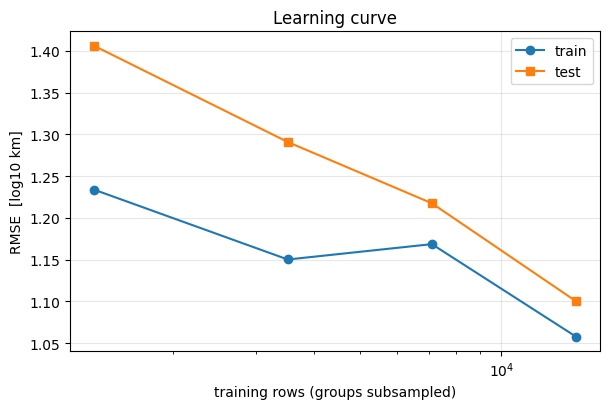

In [15]:
from dataclasses import replace

FRACS = (0.10, 0.25, 0.50, 1.00)
lc = []
for f in FRACS:
    sub = subsample_groups(D['group_id'], tr, f, seed=SEED_SPLIT)
    # An epoch is not a fixed amount of work.  At batch 256 the 10% fold ran
    # five steps per epoch and never left the mean predictor (train RMSE 1.796
    # vs B0's 1.851) -- that was a failed fit being read as a data-size result.
    n_sub = int(sub.sum())
    cfg_f = replace(cfg, batch_size=int(min(cfg.batch_size, max(32, n_sub // 25))))
    mdl, h = train_mlp(Z[sub], y[sub], Z[va], y[va], cfg_f, seed=SEEDS_MODEL[0])
    m_te = regression_metrics(y[te], predict(mdl, Z[te], h))
    m_tr = regression_metrics(y[sub], predict(mdl, Z[sub], h))
    lc.append(dict(frac=f, n_groups=int(len(np.unique(D['group_id'][sub]))),
                   n_rows=int(sub.sum()), train_rmse=m_tr['rmse'],
                   test_rmse=m_te['rmse'], test_r2=m_te['r2'],
                   batch=cfg_f.batch_size, budget_limited=h['hit_max_epochs']))
    print(f"  {f:5.0%}  rows {sub.sum():6d}  batch {cfg_f.batch_size:4d}  "
          f"train RMSE {m_tr['rmse']:.4f}  "
          f"test RMSE {m_te['rmse']:.4f}  test R2 {m_te['r2']:+.4f}")

fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.plot([r['n_rows'] for r in lc], [r['train_rmse'] for r in lc], 'o-', label='train')
ax.plot([r['n_rows'] for r in lc], [r['test_rmse'] for r in lc], 's-', label='test')
ax.set_xscale('log'); ax.set_xlabel('training rows (groups subsampled)')
ax.set_ylabel('RMSE  [log10 km]'); ax.set_title('Learning curve')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

## 8. The two curves

**Left — the deliverable.** Research Question row 9 specifies classification
recovered by thresholding the regression: true class (d < τ), predicted class
(d̂ < τ), agreement swept over τ. It **degenerates to 1 at both ends** — once τ
leaves the data range every sample is one class and any predictor is right — so
the mean or max over τ is meaningless. The honest scalar is the **minimum**,
and balanced accuracy and MCC are shown alongside because the class prior at
each τ is set by the log-uniform draw rather than by anything physical.

**Right — the one the warm-start story wants.** Fraction with |ŷ − y| ≤ tol, in
log₁₀ km. An RMSE of 0.2 in log₁₀ is a typical factor-of-1.6 error in the
distance handed to a solver, which is legible in a way R² is not.

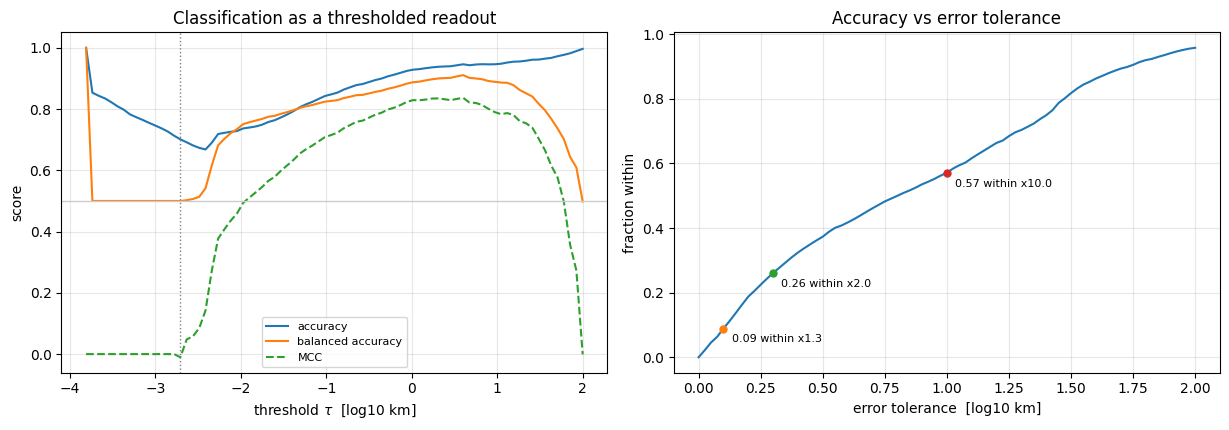

threshold-curve summary (restricted to informative tau):
  n_tau_informative          74
  tau_range                  (-3.7361456304621887, 1.6310093793667462)
  min_balanced_accuracy      0.49982332155477033
  tau_at_min                 -2.706828231316914
  accuracy_at_min            0.7011152416356877
  min_mcc                    -0.010273829610448815
  median_balanced_accuracy   0.8111852693856216


In [16]:
curve = accuracy_vs_threshold(y[te], p_m1, n_tau=80)
summary = summarize_threshold_curve(curve)
etol = accuracy_vs_error_tolerance(y[te], p_m1, tols=np.linspace(0, 2.0, 81))

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.4))
a = axes[0]
a.plot(curve['tau'], curve['accuracy'], label='accuracy')
a.plot(curve['tau'], curve['balanced_accuracy'], label='balanced accuracy')
a.plot(curve['tau'], curve['mcc'], label='MCC', ls='--')
a.axvline(summary.get('tau_at_min', np.nan), color='0.5', lw=1, ls=':')
a.axhline(0.5, color='0.8', lw=1)
a.set_xlabel(r'threshold $\tau$  [log10 km]'); a.set_ylabel('score')
a.set_title('Classification as a thresholded readout')
a.grid(alpha=.3); a.legend(fontsize=8)

b = axes[1]
b.plot(etol['tol'], etol['fraction_within'])
for t in (0.1, 0.3, 1.0):
    f = float(np.interp(t, etol['tol'], etol['fraction_within']))
    b.plot([t], [f], 'o', ms=5)
    b.annotate(f'{f:.2f} within x{10**t:.1f}', (t, f), textcoords='offset points',
               xytext=(6, -10), fontsize=8)
b.set_xlabel('error tolerance  [log10 km]'); b.set_ylabel('fraction within')
b.set_title('Accuracy vs error tolerance')
b.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("threshold-curve summary (restricted to informative tau):")
for k, v in summary.items():
    print(f"  {k:26s} {v}")

## 9. Residuals against the target — the P3 check

Binned on the **target's own magnitude**, not on phase-space location. The
phase-space error map is Week 12; this is only enough to score P3.

measured rows only (at_floor excluded):
 bin_lo   bin_hi    n     bias    rmse     mae
-3.8075  -3.3236  319   1.3458  1.3780  1.3458
-3.3236  -2.8398  257   0.8825  0.9375  0.8825
-2.8398  -2.3559  311   0.4103  0.5165  0.4165
-2.3559  -1.8721  274  -0.0555  0.3231  0.2637
-1.8721  -1.3883  284  -0.5414  0.6414  0.5826
-1.3883  -0.9044  305  -1.0119  1.0527  1.0181
-0.9044  -0.4206  273  -1.2765  1.3279  1.2765
-0.4206   0.0633  288  -1.0251  1.3455  1.1667
 0.0633   0.5471  291  -0.7293  1.2331  0.9621
 0.5471   1.0309  312  -0.2737  0.8845  0.5556
 1.0309   1.5148  300  -0.1925  0.5977  0.3302
 1.5148   1.9986  282  -0.2291  0.5223  0.3113

implied constant output per bin (bias + centre):
  -2.220  -2.199  -2.188  -2.170  -2.172  -2.158  -1.939  -1.204  -0.424  +0.515  +1.080  +1.528

DEAD ZONE: first 6 bins are flat to 0.062
  bias-vs-centre slope -0.976 (-1 means the output ignores the input)
  constant output -2.184 log10 km = 6.5 m
  boundary -0.904 log10 km = 125 m -- below thi

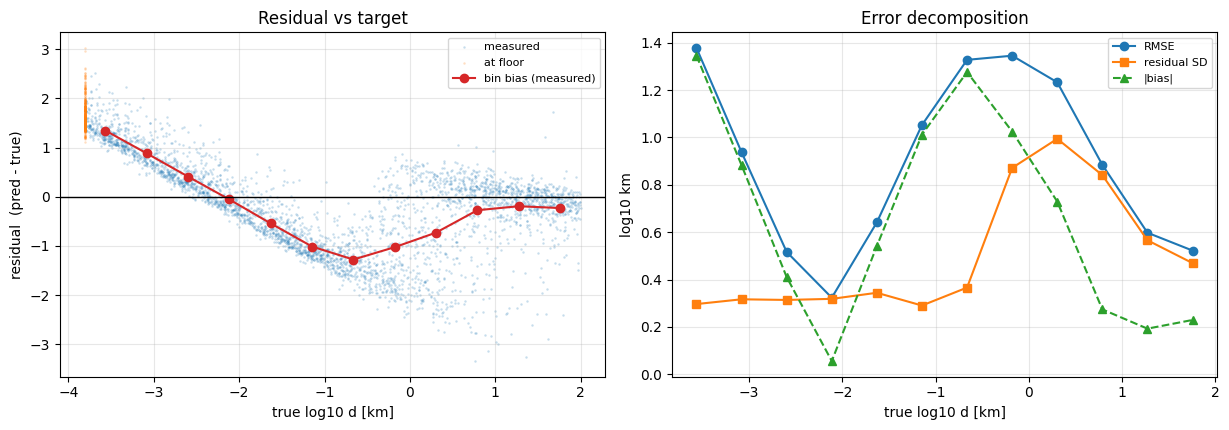

In [17]:
# MEASURED ROWS ONLY. 13% of the test set is pinned at the floor, all of it in
# the smallest-d bins, and left-censoring produces a large positive bias there
# mechanically. Scoring P3 on all rows confounds the two.
rb = residual_bins(y[te][~fl], p_m1[~fl], n_bins=12)
print("measured rows only (at_floor excluded):")
print(format_table(rb, ['bin_lo', 'bin_hi', 'n', 'bias', 'rmse', 'mae']))

ctr = np.array([(r['bin_lo'] + r['bin_hi']) / 2 for r in rb])
bias_b = np.array([r['bias'] for r in rb])
rmse_b = np.array([r['rmse'] for r in rb])
sd_b = np.sqrt(np.maximum(rmse_b ** 2 - bias_b ** 2, 0.0))   # RMSE^2 = bias^2 + var

# IS THERE A DEAD ZONE?  Under mean reversion pred = mu + lam*(y-mu), so
# bias + centre = mu + (lam-1)*... is NOT flat unless lam = 0.  A flat
# (bias + centre) therefore means the model emits a CONSTANT and ignores the
# input over those bins -- a stronger failure than smoothing, and the thing to
# measure.  RMSE alone cannot see it, which is why residual SD is reported.
implied = bias_b + ctr
k = 1
while k < len(implied) and np.ptp(implied[:k + 1]) < 0.10:
    k += 1
print(f"\nimplied constant output per bin (bias + centre):")
print("  " + "  ".join(f"{v:+.3f}" for v in implied))
if k >= 3:
    slope = np.polyfit(ctr[:k], bias_b[:k], 1)[0]
    c0 = float(implied[:k].mean())
    print(f"\nDEAD ZONE: first {k} bins are flat to {np.ptp(implied[:k]):.3f}")
    print(f"  bias-vs-centre slope {slope:+.3f} (-1 means the output ignores the input)")
    print(f"  constant output {c0:+.3f} log10 km = {10**c0*1e3:.1f} m")
    print(f"  boundary {rb[k-1]['bin_hi']:+.3f} log10 km = "
          f"{10**rb[k-1]['bin_hi']*1e3:.0f} m -- below this the regressor does "
          f"not respond to the state")
else:
    print("\nno flat prefix: the near field is tracked, not abandoned")

near, far = [r for r in rb if r['n'] > 0][:3], [r for r in rb if r['n'] > 0][-3:]
nb = float(np.mean([r['bias'] for r in near])); fb = float(np.mean([r['bias'] for r in far]))
nr = float(np.mean([r['rmse'] for r in near])); fr = float(np.mean([r['rmse'] for r in far]))
nsd = float(np.sqrt(max(nr ** 2 - nb ** 2, 0))); fsd = float(np.sqrt(max(fr ** 2 - fb ** 2, 0)))
print(f"\nnear field: bias {nb:+.4f}  RMSE {nr:.4f}  residual SD {nsd:.4f}")
print(f"far  field: bias {fb:+.4f}  RMSE {fr:.4f}  residual SD {fsd:.4f}")
print("\nP3a is scored on residual SD, NOT RMSE. RMSE^2 = bias^2 + variance, so "
      "an\nRMSE comparison counts mean reversion as scatter and reports 'held' "
      "when the\nnear field is in fact the LESS scattered end.")

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.4))
a = axes[0]
a.scatter(y[te][~fl], p_m1[~fl] - y[te][~fl], s=3, alpha=.25, lw=0, label='measured')
a.scatter(y[te][fl], p_m1[fl] - y[te][fl], s=3, alpha=.25, lw=0, color='tab:orange',
          label='at floor')
a.plot(ctr, bias_b, 'o-', color='tab:red', label='bin bias (measured)')
a.axhline(0, color='k', lw=1)
a.set_xlabel('true log10 d [km]'); a.set_ylabel('residual  (pred - true)')
a.set_title('Residual vs target'); a.grid(alpha=.3); a.legend(fontsize=8)

b = axes[1]
b.plot(ctr, rmse_b, 'o-', label='RMSE')
b.plot(ctr, sd_b, 's-', label='residual SD')
b.plot(ctr, np.abs(bias_b), '^--', label='|bias|')
b.set_xlabel('true log10 d [km]'); b.set_ylabel('log10 km')
b.set_title('Error decomposition'); b.grid(alpha=.3); b.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 10. Scorecard

Predictions were stated in the header, before anything ran. Filled in here
against what actually happened, falsifications included.

In [18]:
r2_b1 = results['B1 shortcut']['r2']
r2_g = results['B2 1-NN (grouped)']['r2']
r2_r = results['B2 1-NN (random-row)']['r2']
r2_m1 = results['M1 MLP (seed mean)']['r2']

verdict = {
    'P1 shortcut baseline fails (R2 < 0.5)':
        (r2_b1 < 0.5, f"B1 R2 = {r2_b1:+.4f}"),
    'P2 1-NN gap random > grouped by >0.1':
        (r2_r - r2_g > 0.1, f"random {r2_r:+.4f} vs grouped {r2_g:+.4f}, "
                            f"gap {r2_r - r2_g:+.4f}"),
    'P3a near-field residual SD exceeds far-field':
        (nsd > fsd, f"near SD {nsd:.4f} vs far SD {fsd:.4f} "
                    f"(RMSE {nr:.4f} vs {fr:.4f} -- bias-inflated)"),
    'P3b near-field bias is positive (measured rows only)':
        (nb > 0, f"near-field bias {nb:+.4f}, censored rows excluded"),
    'P3c overall R2 > 0.9 (contradicts Risk 19)':
        (r2_m1 > 0.9, f"M1 R2 = {r2_m1:+.4f}"),
}
for k, (ok, detail) in verdict.items():
    print(f"  [{'HELD' if ok else 'FALSIFIED':9s}] {k}\n              {detail}")

print("\nA falsification here is a result, not a failure.\n")
print("READ P3c CAREFULLY. A falsified P3c means the >0.9 prediction was wrong.")
print("It is NOT evidence for Risk 19's mechanism. Risk 19 attributes mediocre")
print("R2 to Cantor-set non-smoothness, but the labeller measures distance to a")
print("DENSIFIED INTERPOLATED CONTINUUM at ~12.3 km spacing and cannot resolve")
print("the gaps -- that structure is absent from the target as generated. So")
print("Risk 19 stays untested; this experiment has no power over it.\n")
print("P3a and P3b holding is the substantive half: the predicted MECHANISM")
print("(bounded network gradients cannot track grad(log d) ~ 1/d) is visible in")
print("the near-field bias, even though the magnitude prediction failed.\n")
print("If B2 scores near or below zero under BOTH splits, P2 is falsified but")
print("UNINFORMATIVE -- a baseline at zero cannot resolve a gap. The evidence")
print("about row dependence then comes from the group census, not from B2.")

  [HELD     ] P1 shortcut baseline fails (R2 < 0.5)
              B1 R2 = +0.3615
  [FALSIFIED] P2 1-NN gap random > grouped by >0.1
              random -0.0336 vs grouped -0.0305, gap -0.0031
  [FALSIFIED] P3a near-field residual SD exceeds far-field
              near SD 0.3429 vs far SD 0.6267 (RMSE 0.9440 vs 0.6682 -- bias-inflated)
  [HELD     ] P3b near-field bias is positive (measured rows only)
              near-field bias +0.8795, censored rows excluded
  [FALSIFIED] P3c overall R2 > 0.9 (contradicts Risk 19)
              M1 R2 = +0.6576

A falsification here is a result, not a failure.

READ P3c CAREFULLY. A falsified P3c means the >0.9 prediction was wrong.
It is NOT evidence for Risk 19's mechanism. Risk 19 attributes mediocre
R2 to Cantor-set non-smoothness, but the labeller measures distance to a
DENSIFIED INTERPOLATED CONTINUUM at ~12.3 km spacing and cannot resolve
the gaps -- that structure is absent from the target as generated. So
Risk 19 stays untested; this expe

In [19]:
rows = [dict(model=k, **{c: v[c] for c in ('n', 'r2', 'rmse', 'mae', 'bias')})
        for k, v in results.items()]
print(format_table(rows, ['model', 'n', 'r2', 'rmse', 'mae', 'bias']))

out = dict(
    week=11, generated=time.strftime('%Y-%m-%d %H:%M'),
    data=DATA, n_rows=int(n), features=FEAT_NAMES,
    energy_feature='stored sheet C' if SHEET_LIKE else 'stored C (continuous)',
    n_energy_sheets=int(sheets.size),
    energy_leak_corr=float(np.corrcoef(np.log10(dC[_m]), _y[_m])[0, 1])
    if _m.sum() > 50 else None,
    split=dict(seed=SEED_SPLIT, frac_test=FRAC_TEST, frac_val=FRAC_VAL),
    split_report={k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                  for k, v in rep.items()},
    results={k: {kk: float(vv) for kk, vv in v.items()} for k, v in results.items()},
    per_seed_r2=[float(m['r2']) for m in per_seed],
    threshold_summary={k: (list(v) if isinstance(v, tuple) else float(v))
                       for k, v in summary.items()},
    learning_curve=lc,
    residual_bins=rb,
    verdict={k: bool(v[0]) for k, v in verdict.items()},
    config=cfg.__dict__,
)
with open('../data/wk11/results_wk11.json', 'w') as f:
    json.dump(out, f, indent=2, default=str)
np.savez_compressed('../data/wk11/predictions_wk11.npz',
                    test_mask=te, y_test=y[te], pred_seeds=P, pred_mean=p_m1,
                    pred_b1=p_b1, at_floor_test=fl,
                    tau=curve['tau'], acc=curve['accuracy'],
                    bal_acc=curve['balanced_accuracy'], mcc=curve['mcc'],
                    tol=etol['tol'], frac_within=etol['fraction_within'])
print(f"\nsaved -> ../data/wk11/  [{time.time()-t0:.0f}s total]")

               model     n       r2    rmse     mae     bias
             B0 mean  4035  -0.0001  1.8508  1.6207   0.0195
         B1 shortcut  4035   0.3615  1.4789  1.2524   0.0157
   B2 1-NN (grouped)  4035  -0.0305  1.8787  1.4421  -0.3175
B2 1-NN (random-row)  4080  -0.0336  1.8542  1.4095  -0.3444
  M1 MLP (seed mean)  4035   0.6576  1.0830  0.8757   0.0291

saved -> ../data/wk11/  [981s total]


In [20]:
import sys
import numpy as np
sys.path.insert(0, '../src')
from metrics import residual_bins

z = np.load('../data/wk11/predictions_wk11.npz')
y, p, fl = z['y_test'], z['pred_mean'], z['at_floor_test']

print("fraction of test rows whose predicted distance is within a factor of N")
print(f"{'factor':>7s} {'log10 tol':>10s} {'all':>8s} {'measured':>9s}")
for factor in (1.3, 2, 3, 5, 10, 30, 100):
    t = np.log10(factor)
    print(f"{factor:7.1f} {t:10.3f} {np.mean(np.abs(p - y) <= t):8.3f} "
          f"{np.mean(np.abs(p[~fl] - y[~fl]) <= t):9.3f}")

print("\ndead-zone boundary vs bin resolution (measured rows only)")
for nb in (12, 18, 24, 36):
    rb = residual_bins(y[~fl], p[~fl], n_bins=nb)
    ctr = np.array([(r['bin_lo'] + r['bin_hi']) / 2 for r in rb])
    bias = np.array([r['bias'] for r in rb])
    imp = bias + ctr
    k = 1
    while k < len(imp) and np.ptp(imp[:k + 1]) < 0.10:
        k += 1
    if k >= 3:
        print(f"  n_bins={nb:3d}  flat over {k:2d} bins  "
              f"constant {10**imp[:k].mean()*1e3:6.1f} m  "
              f"boundary {10**rb[k-1]['bin_hi']*1e3:7.0f} m  "
              f"slope {np.polyfit(ctr[:k], bias[:k], 1)[0]:+.3f}  "
              f"width {rb[0]['bin_hi']-rb[0]['bin_lo']:.3f} dec")
    else:
        print(f"  n_bins={nb:3d}  no flat prefix")

fraction of test rows whose predicted distance is within a factor of N
 factor  log10 tol      all  measured
    1.3      0.114    0.105     0.121
    2.0      0.301    0.261     0.301
    3.0      0.477    0.363     0.418
    5.0      0.699    0.460     0.531
   10.0      1.000    0.571     0.659
   30.0      1.477    0.802     0.869
  100.0      2.000    0.958     0.966

dead-zone boundary vs bin resolution (measured rows only)
  n_bins= 12  flat over  6 bins  constant    6.5 m  boundary     125 m  slope -0.976  width 0.484 dec
  n_bins= 18  flat over  9 bins  constant    6.6 m  boundary     125 m  slope -0.979  width 0.323 dec
  n_bins= 24  flat over 12 bins  constant    6.6 m  boundary     125 m  slope -0.979  width 0.242 dec
  n_bins= 36  flat over  8 bins  constant    6.2 m  boundary       3 m  slope -0.999  width 0.161 dec


## Carried into Week 12

- `d_res`, if section 2e reported it absent — Week 12's resonance-proximity
  analysis assumes the column exists.
- The censoring split from section 6. If the floor rows carry a large one-signed
  bias, a Tobit loss is the principled fix and it is a Week 12 change.
- Whichever predictions were falsified.
- Risk 18 is marked **Realized** in the tracker: no resonance-adjacent negatives
  were obtainable. Week 12's "connect high-error regions to resonance proximity"
  was written before that. Worth raising with Dr. Lang before Week 12 starts
  rather than discovering it mid-week.

**Still open from Week 10, not Week 11 work:** the project title decision
(Research Question row 13) needs sign-off *before* the STS abstract is written,
and the two STS essays. This week's STS task assumes those drafts exist.